In [2]:
import sys
from pathlib import Path

# Obtiene la ruta absoluta de la raíz del proyecto (sube un nivel desde 'notebooks/')
# Ajusta .parent según dónde esté guardado tu notebook
project_root = Path().resolve().parent 
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

In [3]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [4]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0.0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1.0,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0.0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1.0,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [5]:
df.shape

(891, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


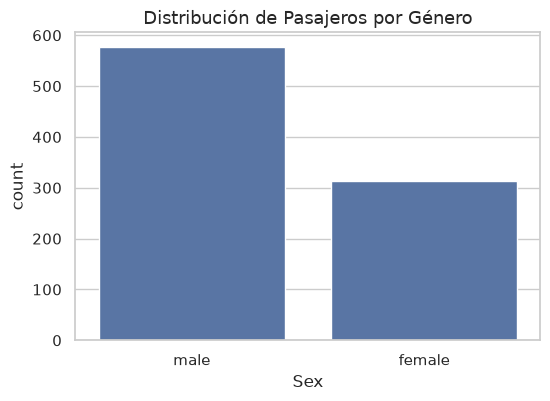

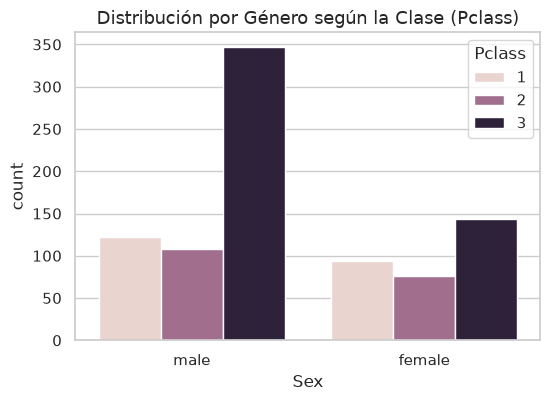

Pclass         1         2         3
Sex                                 
female  0.435185  0.413043  0.293279
male    0.564815  0.586957  0.706721


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico de conteo de 'Sex'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex')
plt.title('Distribución de Pasajeros por Género')
plt.show()

# 2. Gráfico de conteo de 'Sex' con hue='Pclass'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Distribución por Género según la Clase (Pclass)')
plt.show()

# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS
crosstab_norm = pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')
print(crosstab_norm)

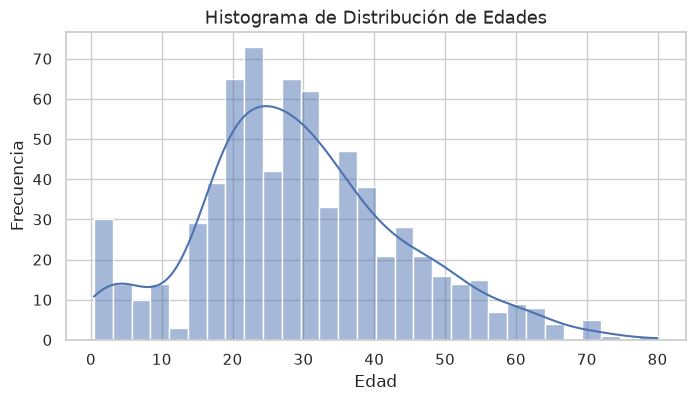

Edad promedio: 29.69911764705882
Mediana de la edad: 28.0
Edad mínima: 0.42
Edad máxima: 80.0


In [10]:
# 1. Histograma de la edad ignorando nulos con dropna()
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'].dropna(), bins=30, kde=True)
plt.title('Histograma de Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

# 2. Edad promedio (Media)
promedio_edad = df['Age'].mean()
print(f"Edad promedio: {promedio_edad}")

# 3. Mediana, mínimo y máximo de la edad
print(f"Mediana de la edad: {df['Age'].median()}")
print(f"Edad mínima: {df['Age'].min()}")
print(f"Edad máxima: {df['Age'].max()}")

In [14]:
import importlib

# Importamos dinámicamente el módulo de ingeniería de datos
de = importlib.import_module("flows.01_data_engineering")

# Aplicamos la función al DataFrame
df = de.add_person(df)

# Realizamos el conteo sin errores
conteo_personas = df['Person'].value_counts()
print(conteo_personas)

Person
male      537
female    271
child      83
Name: count, dtype: int64


In [15]:
# Paso 9: Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas)
tabla_clase_persona = pd.crosstab(df['Pclass'], df['Person'])
print(tabla_clase_persona)

Person  child  female  male
Pclass                     
1           6      91   119
2          19      66    99
3          58     114   319


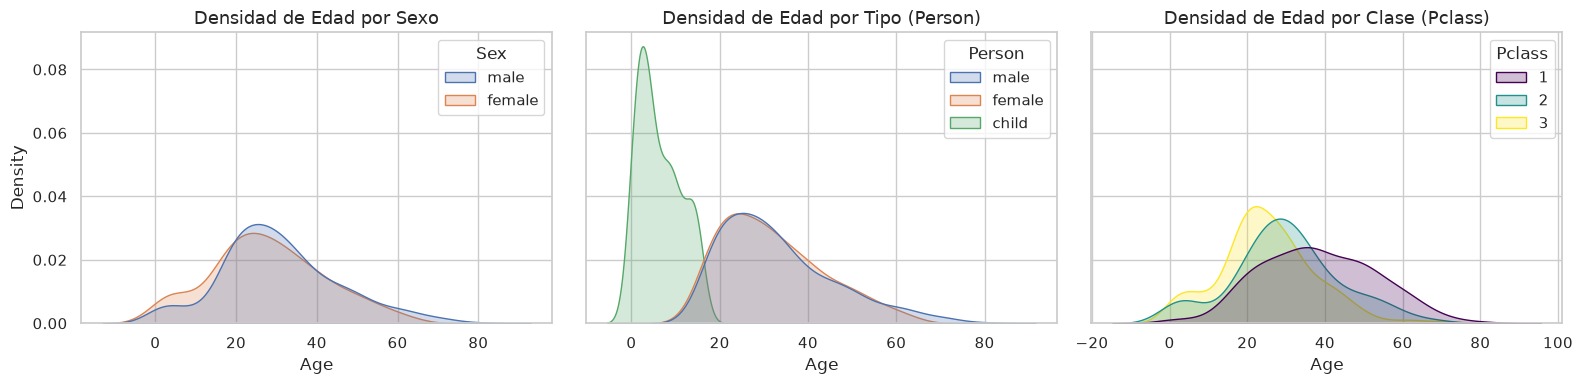

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 10: Gráficos de densidad (KDE) de la edad por diferentes categorías
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Gráfico 1: KDE de Age agrupado por Sex
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Densidad de Edad por Sexo')

# Gráfico 2: KDE de Age agrupado por Person
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Densidad de Edad por Tipo (Person)')

# Gráfico 3: KDE de Age agrupado por Pclass
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Densidad de Edad por Clase (Pclass)')

plt.tight_layout()
plt.show()